Import Libraries

In [93]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import RandomForestClassifier

from sklearn.neighbors import KNeighborsClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

Load Dataset

In [94]:
df = "https://raw.githubusercontent.com/iamjr15/Bank-Loan-Approval-Prediction/master/bankloan.csv"

df = pd.read_csv(df)

df.head(10)

,ID,Age,Experience,Income,ZIP.Code,Family,CCAvg,Education,Mortgage,Personal.Loan,Securities.Account,CD.Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1
5,6,37,13,29,92121,4,0.4,2,155,0,0,0,1,0
6,7,53,27,72,91711,2,1.5,2,0,0,0,0,1,0
7,8,50,24,22,93943,1,0.3,3,0,0,0,0,0,1
8,9,35,10,81,90089,3,0.6,2,104,0,0,0,1,0
9,10,34,9,180,93023,1,8.9,3,0,1,0,0,0,0


Explore Dataset
Display structure

In [101]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIP.Code            5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Personal.Loan       5000 non-null   int64  
 10  Securities.Account  5000 non-null   int64  
 11  CD.Account          5000 non-null   int64  
 12  Online              5000 non-null   int64  
 13  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 547.0 KB


Check shape

In [102]:
df.shape

(5000, 14)

Check datatypes

In [9]:
df.dtypes

ID                      int64
Age                     int64
Experience              int64
Income                  int64
ZIP.Code                int64
Family                  int64
CCAvg                 float64
Education               int64
Mortgage                int64
Personal.Loan           int64
Securities.Account      int64
CD.Account              int64
Online                  int64
CreditCard              int64
dtype: object

Check the total number of duplicates

In [103]:
# Check the number of duplicate rows
print("Dataset shape:", df.shape)

print("Total duplicate rows:", df.duplicated().sum())

Dataset shape: (5000, 14)
Total duplicate rows: 0


Display all rows involved in duplicates

In [104]:
# Display all rows involved in duplicates
duplicates = df[df.duplicated(keep=False)]

print("Total rows involved in duplicate groups:", len(duplicates))

display(duplicates.sort_values(by=df.columns.tolist()))

Total rows involved in duplicate groups: 0


,ID,Age,Experience,Income,ZIP.Code,Family,CCAvg,Education,Mortgage,Personal.Loan,Securities.Account,CD.Account,Online,CreditCard


Check duplicates without the ID column

In [105]:
# Check column names
print(df.columns.tolist())

['ID', 'Age', 'Experience', 'Income', 'ZIP.Code', 'Family', 'CCAvg', 'Education', 'Mortgage', 'Personal.Loan', 'Securities.Account', 'CD.Account', 'Online', 'CreditCard']


In [106]:
# Check for duplicate records excluding applicant ID
cols_to_check = [col for col in df.columns if col != "ID"]

print(
    "Duplicates excluding ID:",
    df.duplicated(subset=cols_to_check).sum()
)

display(
    df[df.duplicated(subset=cols_to_check, keep=False)]
)

Duplicates excluding ID: 0


,ID,Age,Experience,Income,ZIP.Code,Family,CCAvg,Education,Mortgage,Personal.Loan,Securities.Account,CD.Account,Online,CreditCard


Check missing values

In [107]:
#Data quality assessment showed no missing values; therefore, imputation was not required.
df.isnull().sum()

ID                    0
Age                   0
Experience            0
Income                0
ZIP.Code              0
Family                0
CCAvg                 0
Education             0
Mortgage              0
Personal.Loan         0
Securities.Account    0
CD.Account            0
Online                0
CreditCard            0
dtype: int64

Check duplicates

In [108]:
df.duplicated().sum()

0

Statistical Summary
This provides:
MeanStandard deviation,Min,imum,Maximum,Quartiles

Descriptive statistics were computed to understand the central tendency, variability, and distribution of numerical features. Heatmaps, histograms, and boxplots were used to identify trends and potential outliers before model development.

In [109]:
df.describe()

,ID,Age,Experience,Income,ZIP.Code,Family,CCAvg,Education,Mortgage,Personal.Loan,Securities.Account,CD.Account,Online,CreditCard
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000
mean,2500.500000,45.338400,20.104600,73.774200,93152.503000,2.396400,1.937938,1.881000,56.498800,0.096000,0.104400,0.06040,0.596800,0.294000
std,1443.520003,11.463166,11.467954,46.033729,2121.852197,1.147663,1.747659,0.839869,101.713802,0.294621,0.305809,0.23825,0.490589,0.455637
min,1.000000,23.000000,-3.000000,8.000000,9307.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
25%,1250.750000,35.000000,10.000000,39.000000,91911.000000,1.000000,0.700000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
50%,2500.500000,45.000000,20.000000,64.000000,93437.000000,2.000000,1.500000,2.000000,0.000000,0.000000,0.000000,0.00000,1.000000,0.000000
75%,3750.250000,55.000000,30.000000,98.000000,94608.000000,3.000000,2.500000,3.000000,101.000000,0.000000,0.000000,0.00000,1.000000,1.000000
max,5000.000000,67.000000,43.000000,224.000000,96651.000000,4.000000,10.000000,3.000000,635.000000,1.000000,1.000000,1.00000,1.000000,1.000000


The Zip code is dominating but it not important in the dataset 

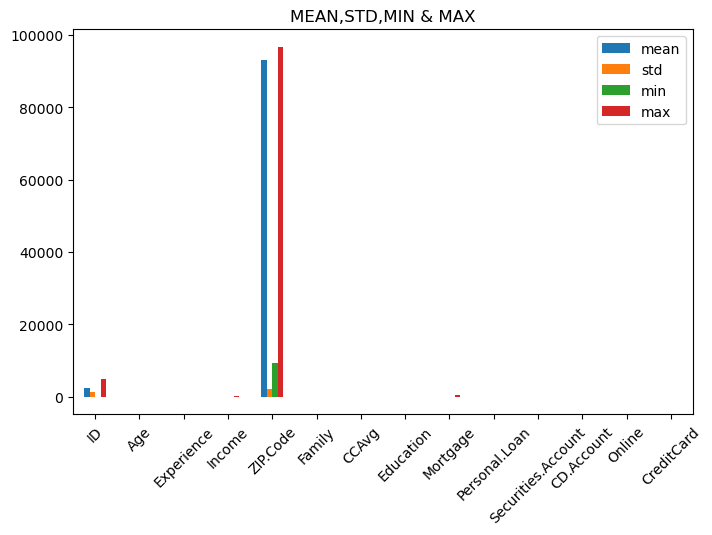

In [110]:

summary = df.describe().T

summary[['mean','std','min','max']].plot(
    kind='bar',
    figsize=(8,5)
)

plt.title('MEAN,STD,MIN & MAX')

plt.xticks(rotation=45)

plt.show()

The zip.Code is still having the majority

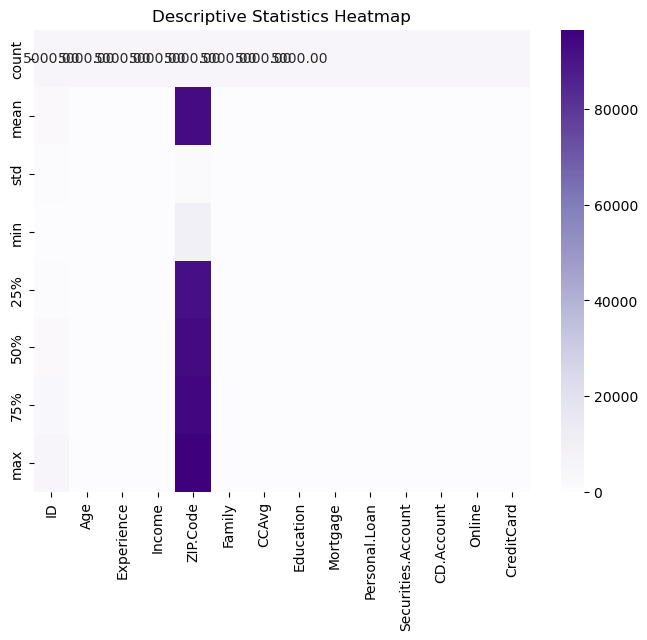

In [111]:
plt.figure(figsize=(8,6))

sns.heatmap(
    df.describe(),
    annot=True,
    cmap='Purples',
    fmt='.2f'
)

plt.title('Descriptive Statistics Heatmap')
plt.show()

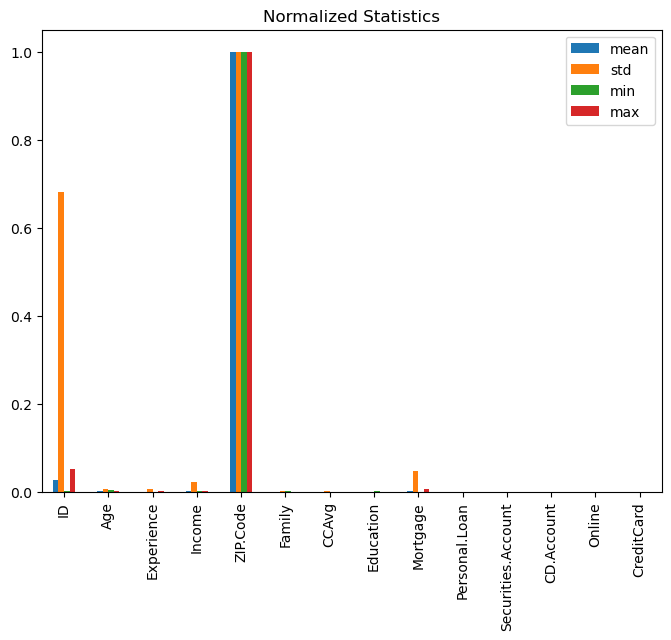

In [112]:
from sklearn.preprocessing import MinMaxScaler

summary = df.describe().T[['mean','std','min','max']]

scaler = MinMaxScaler()

scaled = pd.DataFrame(
    scaler.fit_transform(summary),
    columns=summary.columns,
    index=summary.index
)

scaled.plot(
    kind='bar',
    figsize=(8,6)
)

plt.title('Normalized Statistics')
plt.show()

Zip.code was drop and the true representation of the datase shown

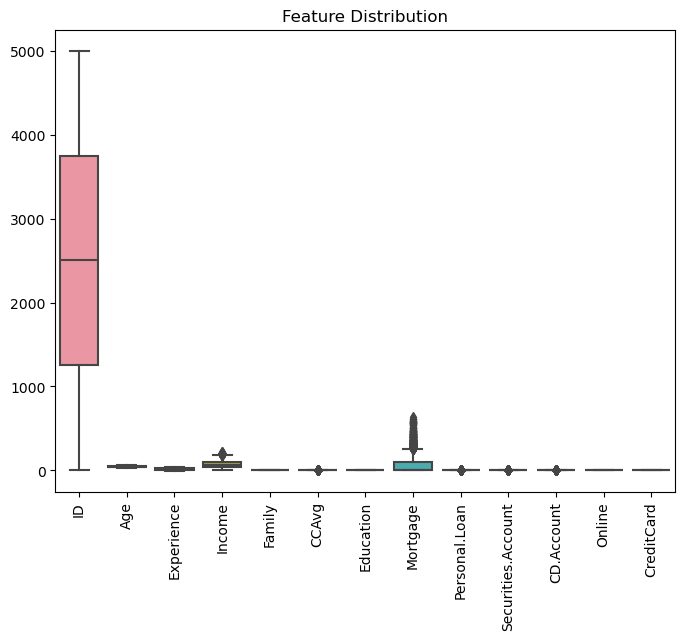

In [113]:
plt.figure(figsize=(8,6))

sns.boxplot(data=df.drop('ZIP.Code', axis=1))

plt.xticks(rotation=90)

plt.title('Feature Distribution')

plt.show()

The ID and ZIP Code variables were excluded from the descriptive statistics visualization because they represent identifiers and location codes rather than meaningful continuous numerical measurements. Excluding these variables improved the interpretability of the statistical analysis.

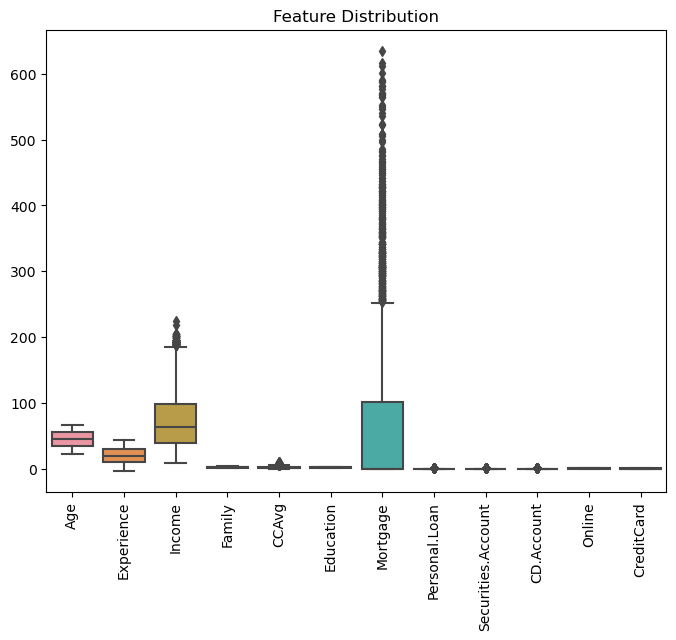

In [114]:
plt.figure(figsize=(8,6))

sns.boxplot(
    data=df.drop(['ZIP.Code', 'ID'], axis=1)
)

plt.xticks(rotation=90)

plt.title('Feature Distribution')

plt.show()

In [115]:
df.head()

,ID,Age,Experience,Income,ZIP.Code,Family,CCAvg,Education,Mortgage,Personal.Loan,Securities.Account,CD.Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


The ID is just a customer identity it has no relationship with the customer loan approval

In [116]:
df.drop('ID', axis=1, inplace=True)

In [117]:
df.head(1)

,Age,Experience,Income,ZIP.Code,Family,CCAvg,Education,Mortgage,Personal.Loan,Securities.Account,CD.Account,Online,CreditCard
0,25,1,49,91107,4,1.6,1,0,0,1,0,0,0


Droping ZIP.CODE althought it might help the model but the model may incorrectly assume ZIP 96789 for  ZIP 12345 since the ZIP is numerical

In [118]:
df.drop('ZIP.Code', axis=1, inplace=True)

In [119]:
df.head(1)

,Age,Experience,Income,Family,CCAvg,Education,Mortgage,Personal.Loan,Securities.Account,CD.Account,Online,CreditCard
0,25,1,49,4,1.6,1,0,0,1,0,0,0


Checking the corrillation between the Age and Experience .
Age and Experience exhibited strong positive correlation, suggesting potential multicollinearity

In [120]:
df[['Age','Experience']].corr()

,Age,Experience
Age,1.000000,0.994215
Experience,0.994215,1.000000


Target Variable Distribution

This plot shows the distribution of approved and non-approved personal loan applications
Check Correlations.The distribution of loan approvals is highly imbalanced, with the majority of customers (class 0) not accepting a personal loan and only a small proportion (class 1) accepting a personal loan.

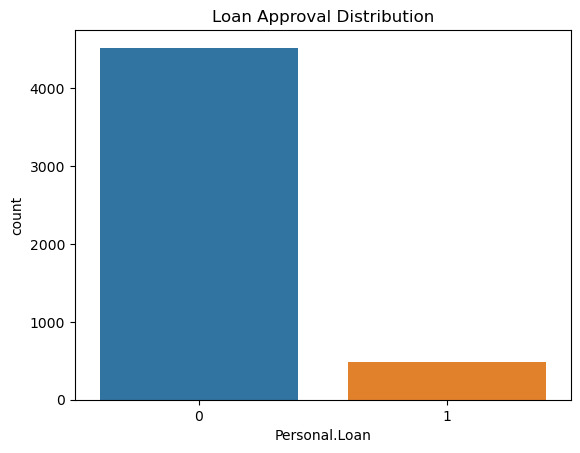

In [121]:
sns.countplot(x='Personal.Loan', data=df)

plt.title('Loan Approval Distribution')

plt.show()

The correlation heatmap shows that Income, CCAvg, and CD.Account have the strongest positive relationships with Personal.Loan, while most other features exhibit weak to moderate correlations.Features with weak correlation were retained during initial model development because low correlation does not necessarily imply low predictive value, particularly for non-linear machine learning algorithms such as Random Forest and Decision Tree.

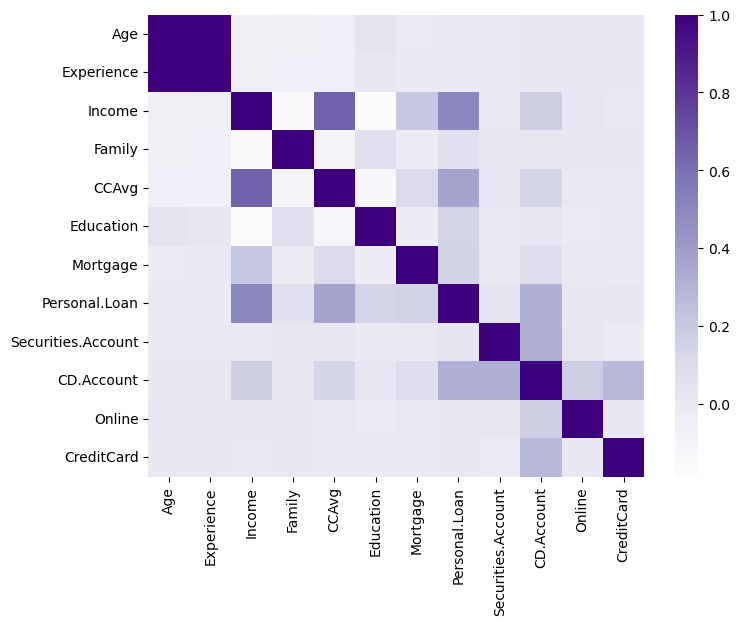

In [122]:
plt.figure(figsize=(8,6))

sns.heatmap(df.corr(), cmap='Purples')

plt.show()

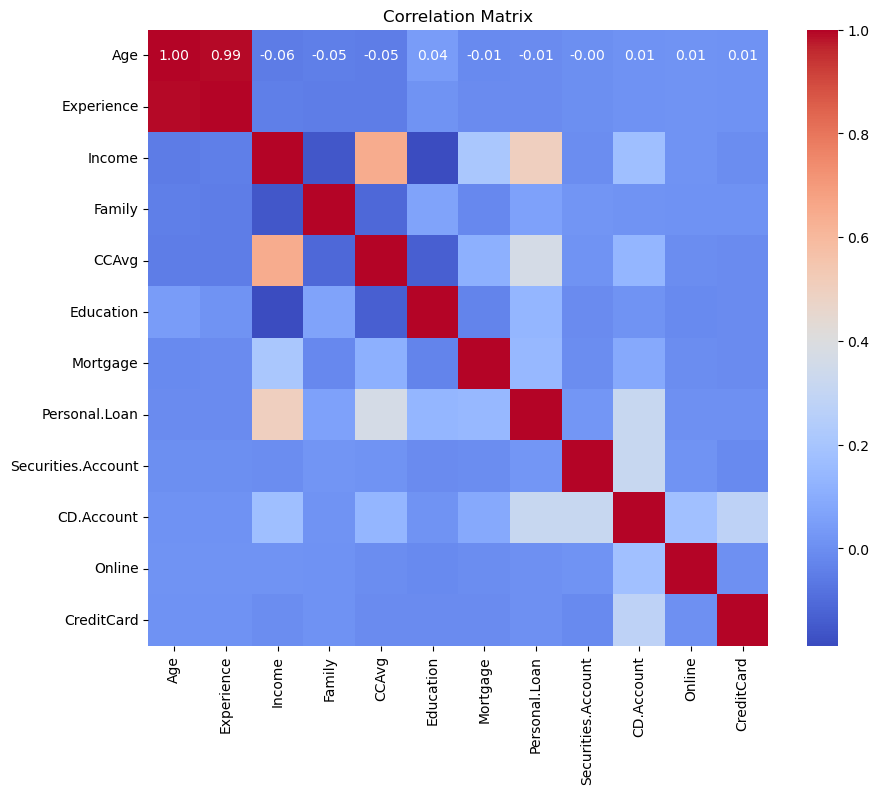

In [43]:
plt.figure(figsize=(10,8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix')

plt.show()

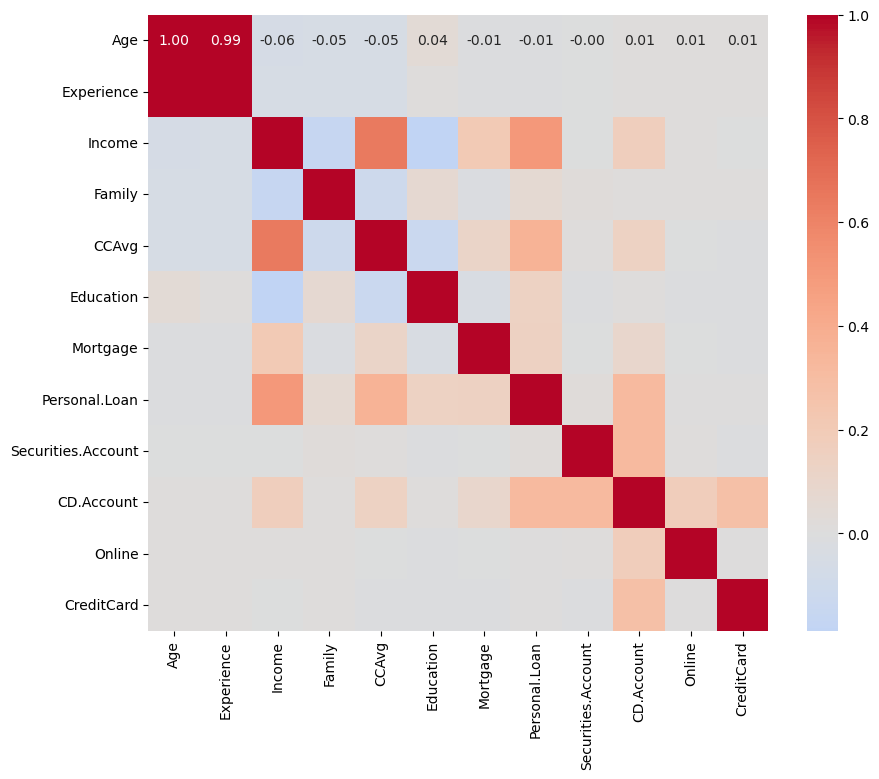

In [123]:
plt.figure(figsize=(10,8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

plt.show()

Below gives a clear understanding of the correlation to every body to understand expercially other who find it difficult to read headmap

In [124]:
corr = df.corr()['Personal.Loan'].sort_values(ascending=False)

print(corr)

Personal.Loan         1.000000
Income                0.502462
CCAvg                 0.366889
CD.Account            0.316355
Mortgage              0.142095
Education             0.136722
Family                0.061367
Securities.Account    0.021954
Online                0.006278
CreditCard            0.002802
Experience           -0.007413
Age                  -0.007726
Name: Personal.Loan, dtype: float64


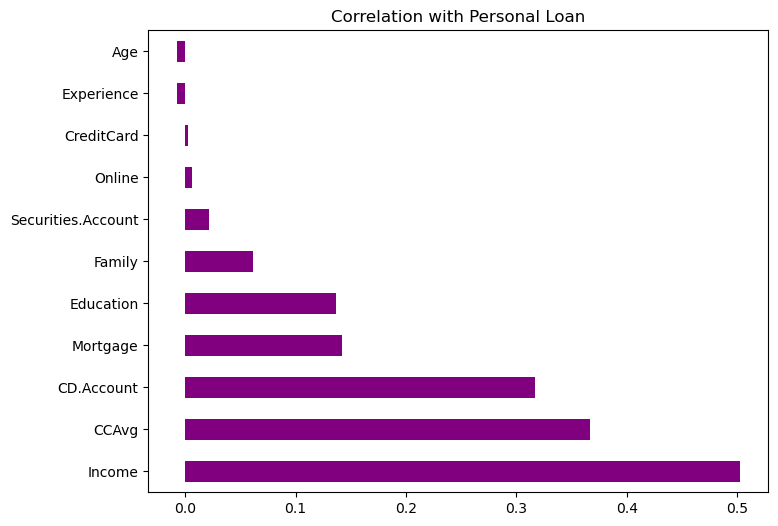

In [125]:
corr.drop('Personal.Loan').plot(
    kind='barh',
    figsize=(8,6),
    color='purple'
)
plt.title('Correlation with Personal Loan')

plt.show()

Check Missing Values Graphically

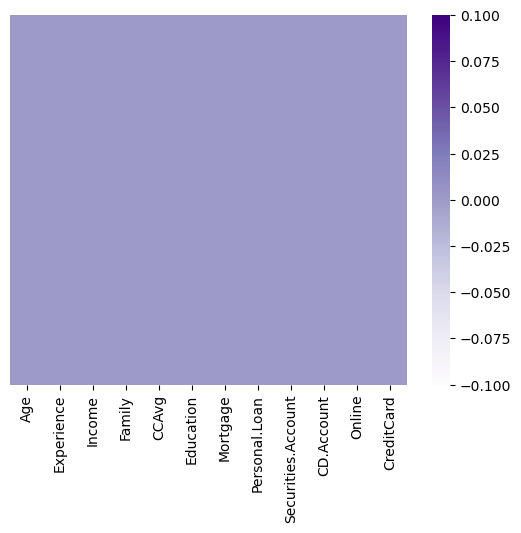

In [126]:
sns.heatmap(df.isnull(),
            yticklabels=False,
            cmap='Purples')

plt.show()

Define X and y

In [127]:
print(df.columns)

Index(['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Education',
       'Mortgage', 'Personal.Loan', 'Securities.Account', 'CD.Account',
       'Online', 'CreditCard'],
      dtype='object')


In [128]:
df.shape

(5000, 12)

target column is:Personal Loan

In [129]:
X = df.drop('Personal.Loan', axis=1)

y = df['Personal.Loan']

Train-Test Split

In [130]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42
)

Feature scaling was applied using StandardScaler to standardize the numerical features. This was particularly important for K-Nearest Neighbors and Logistic Regression, which are sensitive to differences in feature scales and rely on distance or optimization calculations.

Feature Scaling

Important for KNN and Logistic Regression.

In [131]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

Logistic Regression

In [132]:
lr = LogisticRegression(max_iter=1000)

lr.fit(X_train_scaled, y_train)

lr_pred = lr.predict(X_test_scaled)

lr_accuracy = accuracy_score(y_test, lr_pred)

print(lr_accuracy)

0.952


Decision Tree

In [133]:
dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)

dt_accuracy = accuracy_score(y_test, dt_pred)

print(dt_accuracy)

0.98


Random Forest

In [134]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_pred)

print(rf_accuracy)

0.9893333333333333


KNN

In [135]:
knn = KNeighborsClassifier(
    n_neighbors=5
)

knn.fit(X_train_scaled, y_train)

knn_pred = knn.predict(X_test_scaled)

knn_accuracy = accuracy_score(y_test, knn_pred)

print(knn_accuracy)

0.9566666666666667


Naive Bayes

In [136]:
nb = GaussianNB()

nb.fit(X_train, y_train)

nb_pred = nb.predict(X_test)

nb_accuracy = accuracy_score(y_test, nb_pred)

print(nb_accuracy)

0.892


Compare Models

In [137]:
results = pd.DataFrame({

'Model':[
'Logistic Regression',
'Decision Tree',
'Random Forest',
'KNN',
'Naive Bayes'
],

'Accuracy':[
lr_accuracy,
dt_accuracy,
rf_accuracy,
knn_accuracy,
nb_accuracy
]

})

results.sort_values(
    by='Accuracy',
    ascending=False,
    inplace=True
)

print(results)

                 Model  Accuracy
2        Random Forest  0.989333
1        Decision Tree  0.980000
3                  KNN  0.956667
0  Logistic Regression  0.952000
4          Naive Bayes  0.892000


Five machine learning algorithms were evaluated for personal loan prediction. Random Forest achieved the highest accuracy (98.93%) and was selected as the final model. Further evaluation using confusion matrix, classification report, ROC-AUC analysis, and feature importance confirmed its superior performance and suitability for deployment.

Visual Comparison

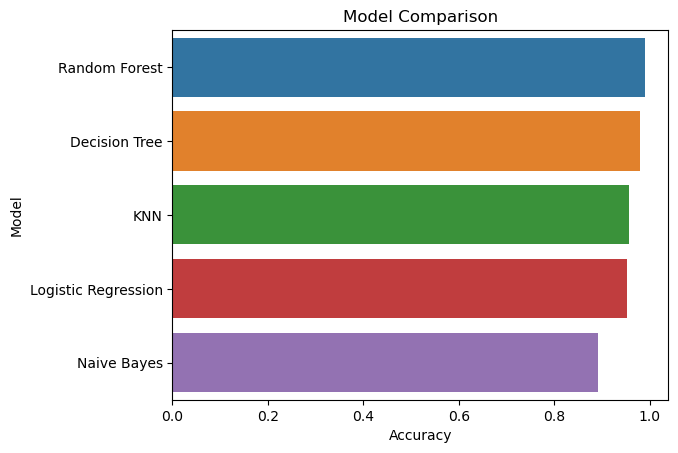

In [138]:
sns.barplot(
    x='Accuracy',
    y='Model',
    data=results
)

plt.title("Model Comparison")

plt.show()

Classification Report
For the best model  : Random Forest


Precision

Recall

F1 Score


In [140]:
print(
classification_report(
y_test,
rf_pred
)
)

              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1343
           1       0.99      0.90      0.95       157

    accuracy                           0.99      1500
   macro avg       0.99      0.95      0.97      1500
weighted avg       0.99      0.99      0.99      1500



Comparing Precision, Recall, and F1-Score.Random forest sttill perform better in all score 

Precision measures the proportion of predicted loan approvals that were actually approved, Recall measures the proportion of actual approved loans correctly identified by the model, and the F1-Score provides a balanced measure of both Precision and Recall. The model with the highest F1-Score was considered the best overall performer.

For your loan dataset, because the target is imbalanced (about 90% vs 10%), F1-Score and Recall are more informative than Accuracy alone. A model can achieve very high accuracy while still performing poorly on the minority loan-approval class.

In [141]:
from sklearn.metrics import precision_score, recall_score, f1_score

metrics = pd.DataFrame({

    'Model':[
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'KNN',
        'Naive Bayes'
    ],

    'Precision':[
        precision_score(y_test, lr_pred),
        precision_score(y_test, dt_pred),
        precision_score(y_test, rf_pred),
        precision_score(y_test, knn_pred),
        precision_score(y_test, nb_pred)
    ],

    'Recall':[
        recall_score(y_test, lr_pred),
        recall_score(y_test, dt_pred),
        recall_score(y_test, rf_pred),
        recall_score(y_test, knn_pred),
        recall_score(y_test, nb_pred)
    ],

    'F1 Score':[
        f1_score(y_test, lr_pred),
        f1_score(y_test, dt_pred),
        f1_score(y_test, rf_pred),
        f1_score(y_test, knn_pred),
        f1_score(y_test, nb_pred)
    ]

})

metrics = metrics.sort_values(
    by='F1 Score',
    ascending=False
)

print(metrics)

                 Model  Precision    Recall  F1 Score
2        Random Forest   0.993007  0.904459  0.946667
1        Decision Tree   0.920530  0.885350  0.902597
3                  KNN   0.933962  0.630573  0.752852
0  Logistic Regression   0.845528  0.662420  0.742857
4          Naive Bayes   0.487047  0.598726  0.537143


In [ ]:
Visual Representative of the Precision, Recall, and F1-Score

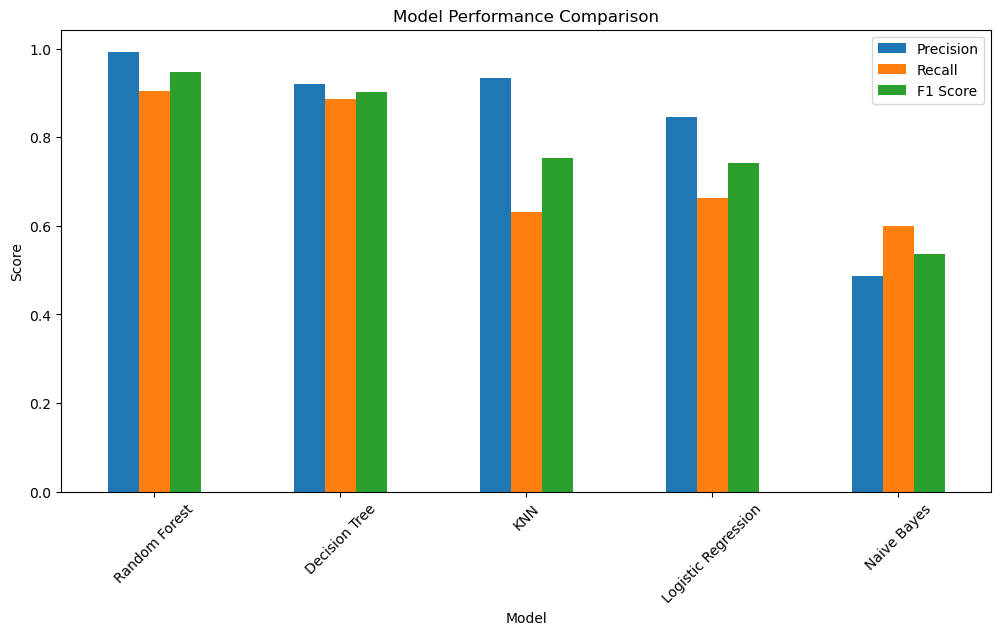

In [142]:
metrics.set_index('Model').plot(
    kind='bar',
    figsize=(12,6)
)

plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.xticks(rotation=45)

plt.show()

The Random Forest model correctly classified 1,484 out of 1,500 customer records, with only 16 misclassifications. It identified 1,342 non-loan customers and 142 loan customers correctly, demonstrating excellent predictive performance with an accuracy of 98.93%.

Very low False Positives (1)

Low False Negatives (15)

High True Positives (142)

High True Negatives (1342)


Confusion Matrix

In [143]:
print("Confusion Matrix:")
print(cm)

TN = cm[0,0]
FP = cm[0,1]
FN = cm[1,0]
TP = cm[1,1]

print(f"True Negatives: {TN}")
print(f"False Positives: {FP}")
print(f"False Negatives: {FN}")
print(f"True Positives: {TP}")

Confusion Matrix:
[[1342    1]
 [  15  142]]
True Negatives: 1342
False Positives: 1
False Negatives: 15
True Positives: 142


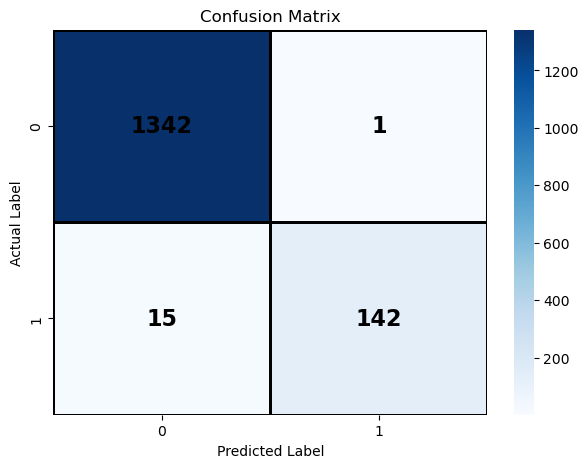

In [144]:
plt.figure(figsize=(7,5))

ax = sns.heatmap(
    cm,
    cmap='Blues',
    cbar=True,
    linewidths=1,
    linecolor='black'
)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(
            j + 0.5,
            i + 0.5,
            str(cm[i, j]),
            ha='center',
            va='center',
            color='black',
            fontsize=16,
            fontweight='bold'
        )

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix')

plt.show()

Feature Importance
This is where the project starts to look professional.

Feature importance analysis revealed that Income (34.28%), Education (18.72%), and CCAvg (16.52%) were the most influential factors in predicting personal loan acceptance, while Securities Account, Online Banking, and Credit Card ownership had minimal impact.

In [145]:
importance = pd.DataFrame({

'Feature': X.columns,

'Importance': rf.feature_importances_

})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print(importance)

               Feature  Importance
2               Income    0.342828
5            Education    0.187240
4                CCAvg    0.165200
3               Family    0.111932
8           CD.Account    0.050375
1           Experience    0.043692
0                  Age    0.039189
6             Mortgage    0.038843
10          CreditCard    0.008283
9               Online    0.008099
7   Securities.Account    0.004320


Plot

Your four most important features are:
- Income — 34.28%
- Education — 18.72%
- CCAvg — 16.52%
- Family — 11.19%

Together, these account for approximately 80.7% of the total importance scores.
This suggests that these variables are particularly influential in your model. However, feature importance does not automatically tell you whether a variable causes loan approval or whether the model is accurate.

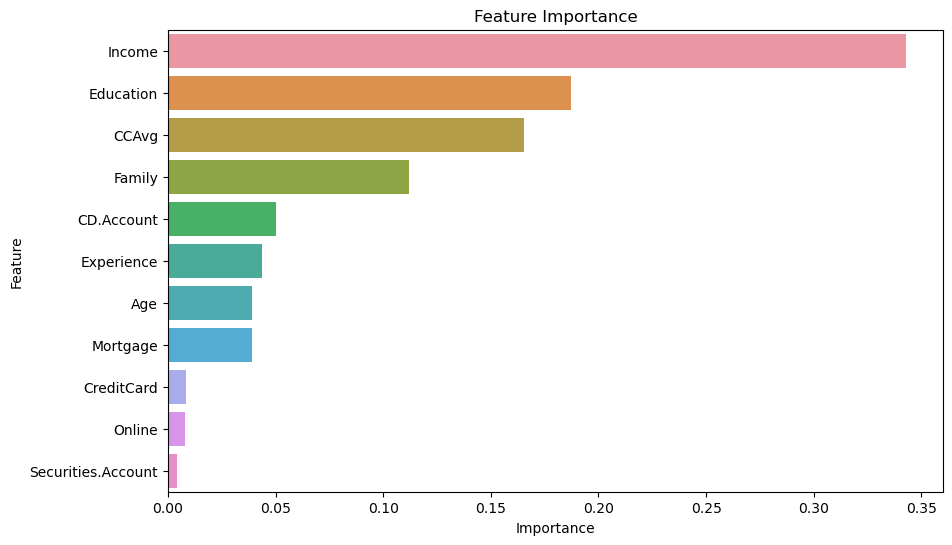

In [146]:
plt.figure(figsize=(10,6))

sns.barplot(
    x='Importance',
    y='Feature',
    data=importance
)

plt.title('Feature Importance')

plt.show()

Hyperparameter Tuning

Hyperparameter tuning helps find settings that improve a model's ability to learn patterns from training data and generalise to unseen data

### Random Forest Model — Hyperparameter Tuning and Evaluation

Hyperparameter tuning identified the best parameters as `max_depth=15`, `min_samples_split=2`, and `n_estimators=100`. The tuned Random Forest achieved a test accuracy of **98.93%**.

The model achieved a precision of 99.30%, recall of 90.45%, and F1-score of 94.67% for class 1. The confusion matrix shows that it correctly classified 1,484 out of 1,500 applicants, with 16 misclassifications.

These results demonstrate strong predictive performance on the test dataset. However, because the classes are imbalanced, precision, recall, F1-score and the confusion matrix are also important when evaluating the model. Its performance should be compared with other candidate models before selecting the final model.

In [147]:
from sklearn.model_selection import GridSearchCV

param_grid = {

'n_estimators':[100,200],

'max_depth':[5,10,15,None],

'min_samples_split':[2,5,10]

}

grid = GridSearchCV(

RandomForestClassifier(),

param_grid,

cv=5,

scoring='accuracy'

)

grid.fit(X_train,y_train)

print(grid.best_params_)

print(grid.best_score_)

{'max_depth': 15, 'min_samples_split': 2, 'n_estimators': 200}
0.984


Check training accuracy vs test accuracy

This helps identify whether your model may be overfitting.

### Overfitting Assessment

The tuned Random Forest achieved 100% training accuracy and 98.93% test accuracy, resulting in an accuracy gap of 1.07 percentage points. Although the perfect training accuracy suggests that the model may fit the training data closely, its high test accuracy indicates strong predictive performance on unseen samples. Cross-validation and data-leakage checks will provide further evidence of the model's reliability and generalisation ability.

In [148]:

from sklearn.metrics import accuracy_score

# Predictions on training and test data
y_train_pred = best_model.predict(X_train)
y_test_pred = best_model.predict(X_test)

# Calculate accuracy
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Accuracy Gap: {train_accuracy - test_accuracy:.4f}")

Training Accuracy: 1.0000
Test Accuracy: 0.9893
Accuracy Gap: 0.0107


### Cross-Validation and Model Reliability

Five-fold stratified cross-validation was performed to assess the consistency of the tuned Random Forest model. The model achieved a mean accuracy of 98.49%, with a standard deviation of 0.15 percentage points across the five folds.

The small variation between folds suggests that the model's accuracy is relatively stable across different data partitions. Combined with the test accuracy of 98.93%, these results provide encouraging evidence of generalisation.

In [149]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
import numpy as np

# Your tuned Random Forest model
rf_model = RandomForestClassifier(
    max_depth=15,
    min_samples_split=2,
    n_estimators=100,
    random_state=42
)

# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate using training data only
cv_scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("Cross-validation scores:", np.round(cv_scores, 4))
print(f"Mean CV Accuracy: {cv_scores.mean():.4f}")
print(f"Standard Deviation: {cv_scores.std():.4f}")


Cross-validation scores: [0.9871 0.9843 0.9843 0.9829 0.9857]
Mean CV Accuracy: 0.9849
Standard Deviation: 0.0015


Save Best Model

In [153]:
import joblib

joblib.dump(rf,
            'loan_approval_model.pkl')

['loan_approval_model.pkl']

In [154]:
import os

print("Model saved in:", os.path.abspath("loan_approval_model.pkl"))

Model saved in: C:\Users\DELL\loan_approval_model.pkl
